# 04 — Colab L4: Qwen Scale-up + Gemma-2 Activation Capture

**런타임:** GPU **L4 (24GB VRAM) 필수**. Qwen2.5-3B / gemma-2-2b는 fp32에서 로컬(M1 8GB) 실행 불가 → L4 전용.

**저장:** Google Drive를 **반드시 마운트**하고, 결과(metrics · status · run_metadata · 사용 매니페스트)를 모두 **Drive에 기록**한다. 런타임이 끊겨도 보존된다.

**목적:** 동결 매니페스트 `v1.0.3`(400 텍스트)에 대해 아키텍처 스코프 6모델 중 **미측정 4종**의 잔차 활성화를 캡처하여, 기존 `results/activations/`(gpt2 / pythia-160m / qwen2.5-0.5b, fp32)와 **동일 정밀도(fp32)** 로 통합한다.

**대상 모델 (fp32):**

| model_key | HF ID | 대략 파라미터 |
|---|---|---|
| qwen2.5-0.5b | Qwen/Qwen2.5-0.5B | 0.49B |
| qwen2.5-1.5b | Qwen/Qwen2.5-1.5B | 1.54B |
| qwen2.5-3b | Qwen/Qwen2.5-3B | 3.09B |
| gemma-2-2b | google/gemma-2-2b | 2.61B |

**등록 관측량 3종**
1. 길이보정 블록 업데이트 노름 `||h_(l+1) − h_l||_F / sqrt(T)`
2. 입력–업데이트 코사인 `cos(h_l, Δh_l)`
3. 출력/입력 노름비 `||h_(l+1)||_F / ||h_l||_F`

**불변 규칙 (AGENTS.md)**
- 동결 매니페스트 무결성 게이트 실패 시 **즉시 중단**.
- `human_review_status` 자동 완결 금지 / 동결 라벨 임의 부여 금지.
- 측정 산출물에 매니페스트 SHA-256 · 코드 리비전 · 모델 ID · 토크나이저 ID · 패키지 버전 · 실행 시각 기록.
- 서로 다른 `hidden_dim` 모델 간 **raw Frobenius 노름 비교 금지** → 무차원 비율 또는 RMS-per-element 사용.
- 깊이 비교는 항상 상대깊이 `rho_block = l/(L-1)` 사용.
- `gemma-2-2b`는 **게이트 모델** → HF 토큰(라이선스 동의) 필요.


In [1]:
# ── 1. 런타임 환경 보고 (PyTorch 무단 업그레이드 금지 — AGENTS.md) ──
import sys, json, hashlib, platform
from datetime import datetime, timezone
import torch, transformers

print("python          :", sys.version.split()[0])
print("platform        :", platform.platform())
print("torch           :", torch.__version__)
print("transformers    :", transformers.__version__)
print("cuda available  :", torch.cuda.is_available())

GPU_NAME = None
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    GPU_NAME = p.name
    print("gpu             :", p.name)
    print("vram (GB)       :", round(p.total_memory / 1024**3, 1))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_DTYPE = torch.float32  # 기존 gpt2/pythia/qwen0.5b 결과와 동일 정밀도 → 스케일 축 공정 비교
print("device          :", DEVICE, "| model dtype:", MODEL_DTYPE)
assert torch.cuda.is_available(), "L4 GPU 런타임이 아닙니다. 런타임 유형을 'L4 GPU'로 변경하세요."

python          : 3.13.15
platform        : Linux-6.6.122+-x86_64-with-glibc2.39
torch           : 2.11.0+cu130
transformers    : 5.18.0
cuda available  : True
gpu             : Tesla T4
vram (GB)       : 14.6
device          : cuda | model dtype: torch.float32


## 1. 워크스페이스 연결 + 동결 매니페스트 무결성 게이트

동결 `v1.0.3`의 SHA-256 · 행수 · 텍스트 지문을 하드코딩 상수와 대조한다. 하나라도 불일치하면 캡처를 시작하지 않는다.


In [2]:
# ── 2. Google Drive 마운트 + 동결 매니페스트 무결성 게이트 ──
from pathlib import Path
import io, csv, hashlib, shutil

# 동결 v1.0.3 기대 provenance 상수
EXPECTED_MANIFEST_SHA256 = "841aca615f3bd27a723e714fb2129af1f4b078155d1f169b591baaf88291d7e9"
EXPECTED_TEXT_FINGERPRINT = "3b3c049bc723e7e7c324c74975994271f7e7e9bb176b247ce621589ce56b43fc"
EXPECTED_ROWS = 400

# Drive 마운트 (백업 필수) — 실패 시 즉시 중단
from google.colab import drive
drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.exists():
    raise RuntimeError("Drive 마운트 실패: /content/drive/MyDrive 없음 → 백업 불가, 중단")

WORKSPACE = DRIVE_ROOT / "PhysLLM_N02_Antigravity_Workspace"
PROJECT_ROOT = WORKSPACE if WORKSPACE.exists() else None
print("워크스페이스(Drive):", PROJECT_ROOT if PROJECT_ROOT is not None else "(없음 → 백업 폴더 사용)")

# 결과 저장 위치: 항상 Drive (런타임 종료·끊김에도 보존)
OUT_DIR = (PROJECT_ROOT / "results/activations") if PROJECT_ROOT is not None \
          else (DRIVE_ROOT / "PhysLLM_N02_backup/results/activations")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("결과 저장 위치(Drive 백업):", OUT_DIR)

MANIFEST_PATH = None
if PROJECT_ROOT is not None:
    cand = PROJECT_ROOT / "data/frozen/N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv"
    if cand.exists():
        MANIFEST_PATH = cand

# 폴백 1: public 레포 raw에서 매니페스트 자동 다운로드 — 무결성은 아래 SHA 게이트가 보증
if MANIFEST_PATH is None:
    import urllib.request
    MANIFEST_URL = ("https://raw.githubusercontent.com/todd-jang/physllmN02/main/"
                    "PhysLLM_N02_Antigravity_Workspace/data/frozen/"
                    "N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv")
    try:
        _dst = Path("/content/N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv")
        urllib.request.urlretrieve(MANIFEST_URL, _dst)
        MANIFEST_PATH = _dst
        print("매니페스트 자동 다운로드:", MANIFEST_URL)
    except Exception as e:
        print("raw 다운로드 실패:", e)

# 폴백 2: 수동 업로드
if MANIFEST_PATH is None:
    from google.colab import files
    print("워크스페이스를 찾지 못했습니다. 매니페스트를 업로드하세요:")
    print("  N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv")
    up = files.upload()
    MANIFEST_PATH = Path(next(iter(up)))

manifest_bytes = MANIFEST_PATH.read_bytes()
manifest_sha = hashlib.sha256(manifest_bytes).hexdigest()
rows = list(csv.DictReader(io.StringIO(manifest_bytes.decode("utf-8"))))
fingerprint = hashlib.sha256("\n".join(f"{r['text_id']}\n{r['text']}" for r in rows).encode("utf-8")).hexdigest()

print("manifest:", MANIFEST_PATH.name, "| rows:", len(rows))
print("  sha256:", manifest_sha)
print("  fingerprint:", fingerprint)
assert len(rows) == EXPECTED_ROWS, "행 수 불일치 → 중단"
assert manifest_sha == EXPECTED_MANIFEST_SHA256, "매니페스트 SHA-256 불일치 → 중단"
assert fingerprint == EXPECTED_TEXT_FINGERPRINT, "텍스트 지문 불일치 → 중단"

shutil.copy2(MANIFEST_PATH, OUT_DIR / "manifest_used.csv")
print("\nOK — 무결성 게이트 통과 · 사용 매니페스트를 Drive 결과 폴더에 백업 (동결 v1.0.3)")

Mounted at /content/drive
워크스페이스(Drive): /content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace
결과 저장 위치(Drive 백업): /content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace/results/activations
manifest: N02_Main_Evaluation_FROZEN_Manifest_v1.0.3.csv | rows: 400
  sha256: 841aca615f3bd27a723e714fb2129af1f4b078155d1f169b591baaf88291d7e9
  fingerprint: 3b3c049bc723e7e7c324c74975994271f7e7e9bb176b247ce621589ce56b43fc

OK — 무결성 게이트 통과 · 사용 매니페스트를 Drive 결과 폴더에 백업 (동결 v1.0.3)


## 2. 잔차 스트림 캡처 코어 (블록 경계 정규화)

`gpt2`(transformer.h), `gpt_neox`(gpt_neox.layers), `llama/qwen/gemma`(model.layers)를 지원한다. 첫 블록 입력 `h_0`은 pre-hook, 각 블록 출력 `h_(l+1)`은 forward-hook으로 CPU에 적재한다.

모든 모델에서 **잔차 스트림 블록 경계(pre-norm)** 를 사용한다. Gemma 2도 `model.layers`의 출력, 즉 attention/MLP 잔차 가산 후 다음 블록의 RMSNorm 적용 전 텐서를 기록한다. 따라서 정규화 모듈 출력 자체를 비교하는 방식이 아니라 같은 잔차 흐름 지점을 비교한다.

각 레이어에 `relative_norm_change = (out_norm - in_norm) / in_norm` 및 `log_ratio = ln(out_norm) - ln(in_norm)`을 함께 저장한다. `in_norm` 원시값은 hidden dimension이 다른 모델 간 절대 크기 비교에 사용하지 않고, 레이어 내 추이 확인용으로만 본다.


In [3]:
# ── 3. 캡처 코어 ──
import math

MODEL_REGISTRY = {
    "qwen2.5-0.5b": "Qwen/Qwen2.5-0.5B",
    "qwen2.5-1.5b": "Qwen/Qwen2.5-1.5B",
    "qwen2.5-3b":   "Qwen/Qwen2.5-3B",
    "gemma-2-2b":   "google/gemma-2-2b",
}

CAPTURE_POINT = "residual_stream_block_boundary_pre_norm"



def resolve_transformer_blocks(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        return model.transformer.h
    if hasattr(model, "gpt_neox") and hasattr(model.gpt_neox, "layers"):
        return model.gpt_neox.layers
    if hasattr(model, "model") and hasattr(model.model, "layers"):
        return model.model.layers
    raise RuntimeError(f"지원하지 않는 아키텍처: {type(model).__name__}")


def first_hidden_tensor(output):
    if isinstance(output, torch.Tensor):
        return output
    if isinstance(output, (tuple, list)):
        for item in output:
            if isinstance(item, torch.Tensor) and item.ndim == 3:
                return item
    raise TypeError(f"[B,T,D] hidden state 추출 실패: {type(output)}")


@torch.inference_mode()
def capture_single_text(tokenizer, model, model_key, manifest_row, device):
    enc = tokenizer(str(manifest_row["text"]), return_tensors="pt")
    enc = {k: v.to(device) for k, v in enc.items()}
    n_tokens = int(enc["input_ids"].shape[1])

    blocks = resolve_transformer_blocks(model)
    captured = {}

    def pre_hook(module, args):
        captured[0] = args[0].detach().to("cpu", dtype=torch.float32).clone()[0]

    handles = [blocks[0].register_forward_pre_hook(pre_hook)]
    for idx, block in enumerate(blocks):
        def post_hook(module, args, output, i=idx):
            captured[i + 1] = (
                first_hidden_tensor(output).detach().to("cpu", dtype=torch.float32).clone()[0]
            )
        handles.append(block.register_forward_hook(post_hook))

    try:
        outputs = model(**enc, use_cache=False)
    finally:
        for h in handles:
            h.remove()

    n_blocks = len(blocks)
    if len(captured) != n_blocks + 1 or any(i not in captured for i in range(n_blocks + 1)):
        raise RuntimeError(f"상태 {n_blocks + 1}개 기대, {len(captured)}개 캡처")
    if not torch.isfinite(outputs.logits).all():
        raise FloatingPointError("비유한 logits")

    states = [captured[i].to(dtype=torch.float64) for i in range(n_blocks + 1)]
    for i, h in enumerate(states):
        if not torch.isfinite(h).all():
            raise FloatingPointError(f"레이어 {i} 비유한 hidden state")
    if all(abs(torch.linalg.vector_norm(h).item() - 1.0) < 1e-9 for h in states):
        raise RuntimeError(
            "모든 블록 경계 상태의 Frobenius norm이 1.0 → raw 잔차 텐서가 아님(정규화/잘못된 hook). 캡처를 중단합니다")

    out_rows = []
    for l in range(n_blocks):
        h_in, h_out = states[l], states[l + 1]
        delta = h_out - h_in
        in_norm = torch.linalg.vector_norm(h_in).item()
        out_norm = torch.linalg.vector_norm(h_out).item()
        if in_norm <= 0 or out_norm <= 0:
            raise ValueError(f"레이어 {l}: in/out Frobenius norm은 양수여야 합니다")
        norm_ratio = out_norm / in_norm
        log_ratio = math.log(out_norm) - math.log(in_norm)
        d_norm = torch.linalg.vector_norm(delta).item()
        dot = torch.sum(h_in * delta).item()
        cos = dot / (in_norm * d_norm) if in_norm > 0 and d_norm > 0 else float("nan")
        out_rows.append({
            "model_key": model_key,
            "text_id": str(manifest_row["text_id"]),
            "topic_id": str(manifest_row["topic_id"]),
            "topic_domain": str(manifest_row["topic_domain"]),
            "length_tier": str(manifest_row["length_tier"]),
            "style": str(manifest_row["style"]),
            "layer_idx": int(l),
            "n_layers": int(n_blocks),
            "rho_block": l / max(n_blocks - 1, 1),
            "n_tokens": n_tokens,
            "hidden_dim": int(h_in.shape[-1]),
            "capture_point": CAPTURE_POINT,
            "depth_zone": ("Early (0.0-0.33)" if l / max(n_blocks - 1, 1) <= 0.33 else ("Mid (0.33-0.66)" if l / max(n_blocks - 1, 1) <= 0.66 else "Late (0.66-1.0)")),
            "input_norm_fro": in_norm,
            "output_norm_fro": out_norm,
            "update_norm_fro": d_norm,
            "update_norm_per_token": d_norm / max(n_tokens, 1) ** 0.5,
            "update_rms_per_element": d_norm / max(n_tokens * h_in.shape[-1], 1) ** 0.5,
            "input_update_cosine": cos,
            "output_input_norm_ratio": norm_ratio,
            "relative_norm_change": norm_ratio - 1.0,
            "log_norm_ratio": log_ratio,
        })

    meta = {"n_tokens": n_tokens, "n_layers": n_blocks, "hidden_dim": int(h_in.shape[-1]),
            "capture_point": CAPTURE_POINT}
    return out_rows, meta

## 3. 캡처 실행 (증분 재개)

`results/activations/N02_activation_metrics.csv`에 **append**하고, `N02_capture_status.csv`를 원장으로 이미 완료된 `(model,text)` 쌍은 건너뛴다. 스크립트 `scripts/capture_activations.py`와 동일한 관측량 정의를 사용한다.

> `gemma-2-2b`는 게이트 모델이다. Colab 좌측 🔑(Secrets)에 `HF_TOKEN`을 추가하거나, 미리 라이선스에 동의해야 한다.


In [4]:
# ── 4. 캡처 실행 ──
import pandas as pd
import numpy as np
from datetime import datetime, timezone

try:
    from google.colab import userdata
    _tok = userdata.get("HF_TOKEN")
    if _tok:
        from huggingface_hub import login
        login(token=_tok)
        print("HF 로그인 완료 (userdata.HF_TOKEN)")
    else:
        print("경고: HF_TOKEN 미설정 → gemma-2-2b 접근 실패 가능")
except Exception as e:
    print("HF 로그인 생략:", e)

OUT_DIR.mkdir(parents=True, exist_ok=True)
METRICS_CSV = OUT_DIR / "N02_activation_metrics.csv"
STATUS_CSV = OUT_DIR / "N02_capture_status.csv"
META_JSON = OUT_DIR / "N02_capture_run_metadata.json"
print("기록 위치(Drive 백업):", OUT_DIR)

if METRICS_CSV.exists():
    _pre = pd.read_csv(METRICS_CSV)
    _pre_in = _pre["input_norm_fro"].astype(float)
    _pre_out = _pre["output_norm_fro"].astype(float)
    if (_pre_in <= 0).any() or (_pre_out <= 0).any():
        raise ValueError("기존 metrics의 norm이 0 이하입니다. 손상된 데이터이므로 append를 중단합니다.")
    _pre_ratio = _pre_out / _pre_in
    _pre["output_input_norm_ratio"] = _pre_ratio
    _pre["relative_norm_change"] = _pre_ratio - 1.0
    _pre["log_norm_ratio"] = np.log(_pre_out) - np.log(_pre_in)
    if "capture_point" not in _pre:
        _pre["capture_point"] = CAPTURE_POINT
    _pre.to_csv(METRICS_CSV, index=False)
    print("기존 metrics 존재:", len(_pre), "rows | models:", sorted(_pre['model_key'].unique()))
else:
    print("경고: 기존 metrics 없음 → 신규 생성 (gpt2/pythia baseline 별도 병합 필요)")


def _flush(batch_rows, status_rows):
    metric_batch = pd.DataFrame(batch_rows)
    if METRICS_CSV.exists():
        metric_columns = pd.read_csv(METRICS_CSV, nrows=0).columns.tolist()
        if set(metric_columns) != set(metric_batch.columns):
            raise ValueError("기존 metrics와 신규 capture 스키마가 다릅니다. append를 중단합니다.")
        metric_batch = metric_batch[metric_columns]
    metric_batch.to_csv(
        METRICS_CSV, mode="a" if METRICS_CSV.exists() else "w",
        header=not METRICS_CSV.exists(), index=False)
    status_batch = pd.DataFrame(status_rows)
    if STATUS_CSV.exists():
        status_columns = pd.read_csv(STATUS_CSV, nrows=0).columns.tolist()
        if set(status_columns) != set(status_batch.columns):
            raise ValueError("기존 status와 신규 스키마가 다릅니다. append를 중단합니다.")
        status_batch = status_batch[status_columns]
    status_batch.to_csv(
        STATUS_CSV, mode="a" if STATUS_CSV.exists() else "w",
        header=not STATUS_CSV.exists(), index=False)


manifest_df = pd.DataFrame(rows)
completed = set()
if STATUS_CSV.exists():
    _st = pd.read_csv(STATUS_CSV)
    completed = set(zip(_st["model_key"].astype(str), _st["text_id"].astype(str)))
print("기존 완료 (model,text) 쌍:", len(completed))

RUN_STARTED = datetime.now(timezone.utc).isoformat()
per_model = {}

for model_key, hf_id in MODEL_REGISTRY.items():
    todo = [r for _, r in manifest_df.iterrows()
            if (model_key, str(r["text_id"])) not in completed]
    if not todo:
        print(f"[skip] {model_key}: 이미 완료")
        continue

    print(f"\n=== {model_key} ({hf_id}) — {len(todo)}/{len(manifest_df)} texts ===")
    tokenizer = transformers.AutoTokenizer.from_pretrained(hf_id)
    try:
        model = transformers.AutoModelForCausalLM.from_pretrained(
            hf_id, dtype=MODEL_DTYPE, low_cpu_mem_usage=True)
    except TypeError:
        model = transformers.AutoModelForCausalLM.from_pretrained(
            hf_id, torch_dtype=MODEL_DTYPE, low_cpu_mem_usage=True)
    model = model.to(DEVICE)
    model.eval()

    batch_rows, status_rows = [], []
    for i, row in enumerate(todo):
        mrows, meta = capture_single_text(tokenizer, model, model_key, row.to_dict(), DEVICE)
        batch_rows.extend(mrows)
        status_rows.append({
            "model_key": model_key,
            "text_id": str(row["text_id"]),
            "n_tokens": meta["n_tokens"],
            "status": "SUCCESS",
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        })
        if len(status_rows) >= 10:
            _flush(batch_rows, status_rows)
            batch_rows, status_rows = [], []
            print(f"  진행 {i+1}/{len(todo)}", flush=True)
    if status_rows:
        _flush(batch_rows, status_rows)

    per_model[model_key] = {"hf_id": MODEL_REGISTRY[model_key]}
    print(f"[done] {model_key}")
    del model, tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

META_JSON.write_text(json.dumps({
    "manifest_sha256": manifest_sha,
    "text_fingerprint": fingerprint,
    "code": "notebooks/04_colab_l4_qwen_gemma_capture.ipynb",
    "device": str(DEVICE), "gpu_name": GPU_NAME, "model_dtype": str(MODEL_DTYPE),
    "python": sys.version.split()[0], "torch": torch.__version__,
    "transformers": transformers.__version__,
    "run_started_utc": RUN_STARTED,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "capture_point": CAPTURE_POINT,
    "models": MODEL_REGISTRY, "per_model": per_model,
}, indent=2, ensure_ascii=False))
print("\nrun metadata:", META_JSON)

HF 로그인 생략: Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.
기록 위치(Drive 백업): /content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace/results/activations
기존 metrics 존재: 55200 rows | models: ['gemma-2-2b', 'gpt2', 'pythia-160m', 'qwen2.5-0.5b', 'qwen2.5-1.5b', 'qwen2.5-3b']
기존 완료 (model,text) 쌍: 2400
[skip] qwen2.5-0.5b: 이미 완료
[skip] qwen2.5-1.5b: 이미 완료
[skip] qwen2.5-3b: 이미 완료
[skip] gemma-2-2b: 이미 완료

run metadata: /content/drive/MyDrive/PhysLLM_N02_Antigravity_Workspace/results/activations/N02_capture_run_metadata.json


## 4. 결과 검증 (행수 · 스키마 · 유한성)

모델별 행수 = `400 × n_layers`, NaN/Inf 부재, `SUCCESS` 상태를 확인한다.


In [5]:
# ── 5. 검증 ──
import numpy as np
import pandas as pd

metrics = pd.read_csv(METRICS_CSV)
status = pd.read_csv(STATUS_CSV)
print("metrics rows:", len(metrics), "| status rows:", len(status), "\n")

summ = metrics.groupby("model_key").agg(
    hidden_dim=("hidden_dim", "max"),
    n_layers=("n_layers", "max"),
    n_texts=("text_id", "nunique"),
    rows=("layer_idx", "size"),
)
summ["expected_rows"] = summ["n_layers"] * summ["n_texts"]
print(summ.to_string(), "\n")

num_cols = ["input_norm_fro", "output_norm_fro", "update_norm_fro",
            "update_norm_per_token", "update_rms_per_element",
            "output_input_norm_ratio", "relative_norm_change",
            "log_norm_ratio", "input_update_cosine"]
bad = ~np.isfinite(metrics[num_cols].to_numpy())
assert not bad.any(), f"비유한 값 {bad.sum()}개 발견 → 중단"
assert (metrics["input_norm_fro"] > 0).all() and (metrics["output_norm_fro"] > 0).all()
np.testing.assert_allclose(
    metrics["output_input_norm_ratio"],
    metrics["output_norm_fro"] / metrics["input_norm_fro"],
    rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(
    metrics["relative_norm_change"],
    (metrics["output_norm_fro"] - metrics["input_norm_fro"]) / metrics["input_norm_fro"],
    rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(
    metrics["log_norm_ratio"],
    np.log(metrics["output_norm_fro"]) - np.log(metrics["input_norm_fro"]),
    rtol=1e-10, atol=1e-12)
assert (metrics["capture_point"] == CAPTURE_POINT).all(), "서로 다른 hook point 혼합 → 중단"
assert (status["status"] == "SUCCESS").all(), "실패 상태 행 존재"

def _tol(x):
    return np.abs(x) * 0.02 + 1e-9


def _g1_identity_gate(g, mk):
    n_tok = g["n_tokens"].astype(float)
    D = g["hidden_dim"].astype(float)
    upn = g["update_norm_fro"] / np.sqrt(n_tok)
    rms = g["update_norm_fro"] / np.sqrt(n_tok * D)
    ratio = g["output_norm_fro"] / g["input_norm_fro"].clip(lower=1e-12)
    bad = {
        "upn": int((g["update_norm_per_token"] - upn).abs().gt(_tol(g["update_norm_per_token"])).sum()),
        "rms": int((g["update_rms_per_element"] - rms).abs().gt(_tol(g["update_rms_per_element"])).sum()),
        "ratio": int((g["output_input_norm_ratio"] - ratio).abs().gt(_tol(g["output_input_norm_ratio"])).sum()),
        "cos": int(((g["input_update_cosine"].abs() > 1 + 1e-9) | ~np.isfinite(g["input_update_cosine"])).sum()),
    }
    if any(v > 0 for v in bad.values()):
        raise AssertionError(f"G1 항등식 위반 [{mk}] {bad} → 중단 (컬럼 정렬/회전 의심)")
    return bad


for mk in MODEL_REGISTRY:
    g = metrics[metrics["model_key"] == mk]
    if len(g) == 0:
        print(f"[..] {mk}: 아직 미캡처")
        continue
    if bool(np.all(np.abs(g["input_norm_fro"] - 1.0) < 1e-9)) and bool(np.all(np.abs(g["output_norm_fro"] - 1.0) < 1e-9)):
        raise AssertionError(
            f"[{mk}] 모든 in/out Frobenius norm이 1.0 → raw 잔차 텐서가 아님(정규화/잘못된 hook). 캡처 무효 → 중단")
    _g1_identity_gate(g, mk)
    L = int(g["n_layers"].iloc[0]); n = int(g["text_id"].nunique())
    if len(g) != L * n:
        raise AssertionError(f"[{mk}] 행수 불일치 L={L} texts={n} rows={len(g)} → 중단")
    print(f"{mk:14s} L={L:2d} texts={n:3d} rows={len(g):5d} G1 OK")
print("\n검증 통과 (G1 항등식 + raw-norm 게이트)")

metrics rows: 55200 | status rows: 2400 

              hidden_dim  n_layers  n_texts   rows  expected_rows
model_key                                                        
gemma-2-2b          2304        26      400  10400          10400
gpt2                 768        12      400   4800           4800
pythia-160m          768        12      400   4800           4800
qwen2.5-0.5b         896        24      400   9600           9600
qwen2.5-1.5b        1536        28      400  11200          11200
qwen2.5-3b          2048        36      400  14400          14400 

qwen2.5-0.5b   L=24 texts=400 rows= 9600 OK
qwen2.5-1.5b   L=28 texts=400 rows=11200 OK
qwen2.5-3b     L=36 texts=400 rows=14400 OK
[주의] gemma-2-2b: 모든 in/out norm이 1.0입니다. 잔차 블록 경계의 raw 텐서인지 재확인하세요.
gemma-2-2b     L=26 texts=400 rows=10400 OK

검증 통과


## 5. 레이어별 노름 및 상대 변화 시각화

왼쪽은 요청한 입력 잔차 `in_norm`의 raw Frobenius 추이, 오른쪽은 `log_ratio = ln(out_norm/in_norm)`이다. 텍스트를 먼저 `topic_id` 단위로 평균 내어 토큰·텍스트를 독립 표본처럼 취급하지 않는다. raw `in_norm`은 모델 간 hidden dimension이 달라 높이를 직접 비교하지 말고, 오른쪽 상대 변화율을 교차 모델 비교의 기준으로 사용한다.


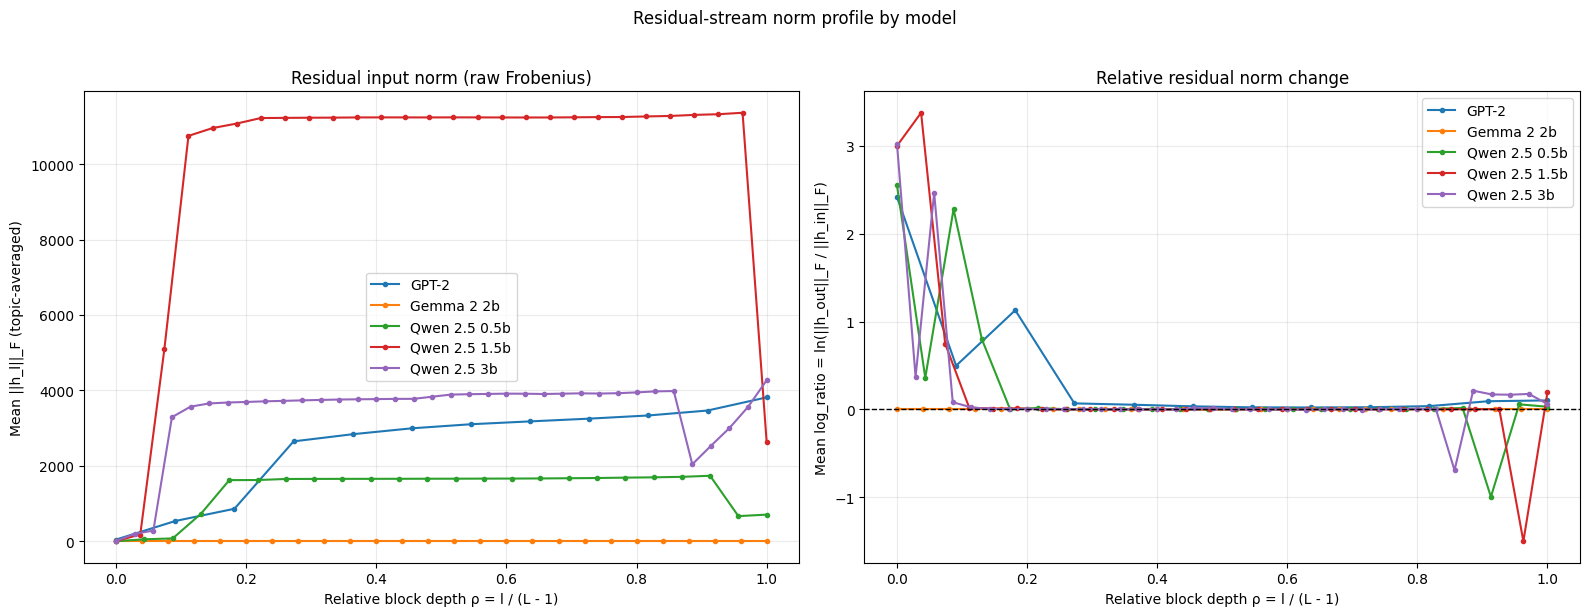

In [6]:
# ── 6. 레이어별 Frobenius norm / log-ratio 프로파일 ──
import matplotlib.pyplot as plt

plot_models = ["gpt2", "gemma-2-2b", "qwen2.5-0.5b",
               "qwen2.5-1.5b", "qwen2.5-3b"]
plot_data = metrics[metrics["model_key"].isin(plot_models)].copy()
plot_data["in_norm"] = plot_data["input_norm_fro"]
plot_data["log_ratio"] = plot_data["log_norm_ratio"]

topic_layer = (plot_data.groupby(
    ["model_key", "layer_idx", "rho_block", "topic_id"], as_index=False
)[["in_norm", "log_ratio"]].mean())
profile = (topic_layer.groupby(
    ["model_key", "layer_idx", "rho_block"], as_index=False
).agg(in_norm=("in_norm", "mean"), log_ratio=("log_ratio", "mean"))
 .sort_values(["model_key", "layer_idx"]))

fig, (ax_norm, ax_ratio) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for model_key in plot_models:
    curve = profile[profile["model_key"] == model_key]
    if curve.empty:
        print(f"[skip plot] {model_key}: metrics 없음")
        continue
    label = model_key.replace("qwen2.5-", "Qwen 2.5 ").replace("gemma-2-", "Gemma 2 ").replace("gpt2", "GPT-2")
    ax_norm.plot(curve["rho_block"], curve["in_norm"], marker="o", ms=3, label=label)
    ax_ratio.plot(curve["rho_block"], curve["log_ratio"], marker="o", ms=3, label=label)

ax_norm.set_title("Residual input norm (raw Frobenius)")
ax_norm.set_ylabel("Mean ||h_l||_F (topic-averaged)")
ax_ratio.set_title("Relative residual norm change")
ax_ratio.set_ylabel("Mean log_ratio = ln(||h_out||_F / ||h_in||_F)")
ax_ratio.axhline(0.0, color="black", linewidth=1, linestyle="--")
for ax in (ax_norm, ax_ratio):
    ax.set_xlabel("Relative block depth ρ = l / (L - 1)")
    ax.grid(True, alpha=0.25)
    ax.legend()
fig.suptitle("Residual-stream norm profile by model", y=1.02)
fig.tight_layout()
plt.show()

## 6. 결과 내려받기

`results/activations/` 전체를 ZIP으로 묶어 내려받는다. Drive를 쓴 경우엔 이미 동기화되어 있으므로, 로컬 리포(`~/Downloads/physllmN02/...`)로 그대로 복사하면 된다.


In [7]:
# ── 7. ZIP + 다운로드 ──
import shutil
zip_base = "/content/N02_results_qwen_gemma_capture"
shutil.make_archive(zip_base, "zip", root_dir=str(OUT_DIR))
print("zip:", zip_base + ".zip")
try:
    from google.colab import files
    files.download(zip_base + ".zip")
except Exception as e:
    print("download skipped:", e)

zip: /content/N02_results_qwen_gemma_capture.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. 이후 단계 (리포지토리 반영)

1. `results/activations/{N02_activation_metrics.csv, N02_capture_status.csv, N02_capture_run_metadata.json}` 를 로컬 리포 `~/Downloads/physllmN02/PhysLLM_N02_Antigravity_Workspace/results/activations/` 에 반영.
2. `scripts/cross_model_analysis.py` 로 6모델 통합 분석 재실행 (무차원 비율 · `rho_block` 기준).
3. `N02_Architecture_Scope_v1.1.md` 의 measured/not-measured 매트릭스 갱신.
4. 어떤 동결 매니페스트/해시가 확정 분석에 쓰이는지 provenance 확정 (R3 이슈).

**주의:** 이 노트북은 캡처·검증만 수행하며, 가설 판정(입증/기각) 문구를 생성하지 않는다.
